# Northern Beaches Water Quality — Exceedance Prediction
ENGG2112 · AI for Good

**Goal:** predict whether the next Beachwatch sample at a site will exceed the enterococci guideline (poor = 1, safe = 0).

**Pipeline:** config → load/clean → label → EDA checks → BOM merge → features → chronological split → models (LR / RF / XGBoost) → evaluation

## 0. Imports
If XGBoost isn't installed, run `pip install xgboost` in a terminal first.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)
from xgboost import XGBClassifier

## 1. Config
Change things here, not further down.
- `SITES`: `'all'` uses every site, or give a list of exact names from the `Swim site` column.
- `FOCUS_SITE`: the site we care most about. Section 11 checks whether training on all sites helps it.
- `THRESHOLD`: poor = enterococci **≥** 41 CFU/100 mL. ⚠️ Check the comparator (≥ vs >) against the NHMRC/Beachwatch source and cite it.
- `BOM_PRIMARY` / `BOM_BACKUP`: daily rainfall stations. Primary is used first; backup fills its gaps.
- `SPLIT_DATE`: everything before → train, on/after → test (chronological).

In [3]:
DATA_PATH = 'Water quality-Data.csv'
BOM_PRIMARY = 'IDCJAC0009_066126_1800_Data.csv'   # Collaroy (Long Reef Golf Club)
BOM_BACKUP = 'IDCJAC0009_066141_1800_Data.csv'    # Mona Vale Golf Club (ends Feb 2025)

SITES = 'all'           # or e.g. ['Narrabeen Lagoon (Birdwood Park)', 'Bilarong Reserve']
FOCUS_SITE = 'Narrabeen Lagoon (Birdwood Park)'
THRESHOLD = 41
SPLIT_DATE = '2021-01-01'
RANDOM_STATE = 42

## 2. Load & clean

In [4]:
df = pd.read_csv(DATA_PATH, encoding='utf-8-sig')   # utf-8-sig strips the BOM char on the first header
df = df.rename(columns={
    'Swim site': 'site',
    'Enterococci (cfu/100mL)': 'entero',
    'Water temperature (°C)': 'water_temp',
})
df['date'] = pd.to_datetime(df['Date'], dayfirst=True)

print('All sites:', df['site'].nunique())
if SITES != 'all':
    df = df[df['site'].isin(SITES)]
df = df.copy()
print('Rows for selected sites:', len(df))

All sites: 42
Rows for selected sites: 55507


In [5]:
# Missing values before dropping
print(df[['entero', 'water_temp']].isna().sum())

# Water temp has entry errors (e.g. 245, 1616 °C) -> treat implausible values as missing
df.loc[~df['water_temp'].between(5, 35), 'water_temp'] = np.nan

df = df.dropna(subset=['entero'])
df = df.sort_values(['site', 'date']).reset_index(drop=True)
df[['site', 'date', 'entero', 'water_temp']].head()

entero          135
water_temp    23886
dtype: int64


,site,date,entero,water_temp
0,Avalon Beach,2000-01-04,0.0,NaN
1,Avalon Beach,2000-01-11,6.0,NaN
2,Avalon Beach,2000-01-16,12.0,NaN
3,Avalon Beach,2000-01-22,90.0,NaN
4,Avalon Beach,2000-01-28,6.0,NaN


## 3. Target label + class balance

In [6]:
df['poor'] = (df['entero'] >= THRESHOLD).astype(int)

print(df.groupby('site')['poor'].agg(['count', 'mean']).rename(columns={'mean': 'exceed_rate'})
      .sort_values('exceed_rate', ascending=False))

                                  count  exceed_rate
site                                                
Bilarong Reserve                    722     0.324100
Narrabeen Lagoon (Birdwood Park)   1230     0.286992
Davidson Reserve                   1224     0.246732
Sangrado Baths                      593     0.241147
Bayview Baths                      1213     0.228359
Salt Pan Cove Baths                 594     0.178451
Gurney Crescent Baths              1225     0.164898
Queenscliff Beach                  1576     0.145939
Winji Jimmi Bay                     594     0.136364
Shelly Beach (Manly)               1576     0.131345
Clontarf Pool                      1226     0.122349
South Steyne Beach                 1571     0.117123
Little Manly Cove                  1225     0.115918
Manly Cove                         1225     0.107755
Paradise Beach Baths               1215     0.104527
Forty Baskets Pool                 1224     0.099673
Clareville Beach                   1215     0.

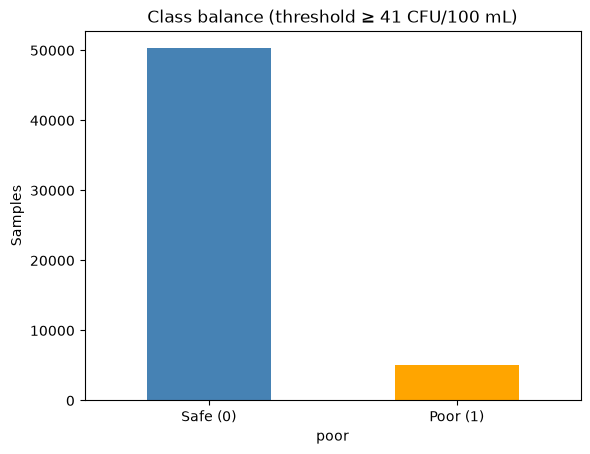

In [7]:
df['poor'].value_counts().sort_index().plot(kind='bar', color=['steelblue', 'orange'])
plt.xticks([0, 1], ['Safe (0)', 'Poor (1)'], rotation=0)
plt.ylabel('Samples')
plt.title(f'Class balance (threshold ≥ {THRESHOLD} CFU/100 mL)')
plt.show()

## 4. EDA sanity checks
Sampling interval (should be ~6 days) and exceedance over time (watch for drift between train and test years).

In [8]:
gaps = df.groupby('site')['date'].diff().dt.days
print(gaps.describe())

count    55330.000000
mean         6.877300
std          4.632439
min          0.000000
25%          6.000000
50%          6.000000
75%          7.000000
max        124.000000
Name: date, dtype: float64


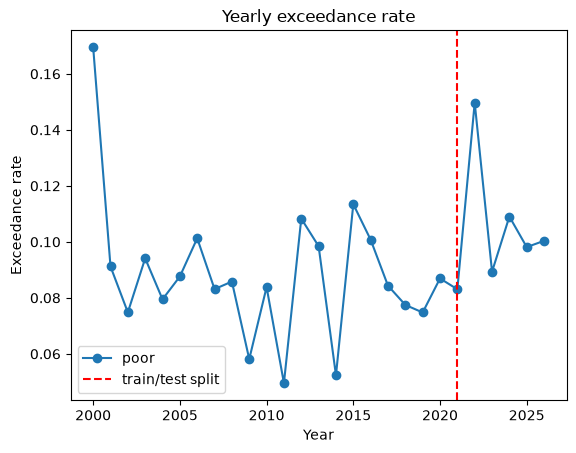

In [9]:
yearly = df.groupby(df['date'].dt.year)['poor'].mean()
yearly.plot(marker='o')
plt.axvline(pd.Timestamp(SPLIT_DATE).year, color='red', ls='--', label='train/test split')
plt.ylabel('Exceedance rate'); plt.xlabel('Year'); plt.legend()
plt.title('Yearly exceedance rate')
plt.show()

## 5. BOM rainfall merge
Two stations: **Collaroy (066126)** is primary (better coverage, runs to Sep 2026). **Mona Vale (066141)** fills Collaroy's gaps (it ends Feb 2025 and is missing ~38% of 2014–16).

Notes:
- BOM's `Period over which rainfall was measured (days)` > 1 means the value is a multi-day total (e.g. after a weekend). We spread it evenly over those days.
- `Quality` = N means not yet quality-controlled by BOM. Kept for now.
- ⚠️ To verify: BOM daily rainfall for date D is the 24h to **9am on D**, so `rain_24h` on a sample date should be known by a morning sample. Confirm against BOM's documentation and cite it.

In [10]:
def load_bom_rainfall(path):
    """Return a daily Series of rainfall (mm) indexed by date, multi-day totals spread evenly."""
    b = pd.read_csv(path)
    b['date'] = pd.to_datetime(b[['Year', 'Month', 'Day']])
    b = b.rename(columns={'Rainfall amount (millimetres)': 'rain',
                          'Period over which rainfall was measured (days)': 'period'})
    rain = b.set_index('date')['rain'].copy()

    # Spread accumulated totals back over the days they cover
    for date, row in b[b['period'] > 1].set_index('date').iterrows():
        days = pd.date_range(end=date, periods=int(row['period']))
        rain.loc[days] = row['rain'] / row['period']
    return rain

rain_primary = load_bom_rainfall(BOM_PRIMARY)
rain_backup = load_bom_rainfall(BOM_BACKUP)

print('Correlation between stations:', rain_primary.corr(rain_backup).round(3))
rain = rain_primary.combine_first(rain_backup)   # primary first, backup fills gaps
study = slice(df['date'].min(), df['date'].max())
print('Days filled from backup (study period):',
      (rain_primary.isna() & rain_backup.notna()).loc[study].sum())

Correlation between stations: 0.813
Days filled from backup (study period): 113


In [11]:
# Cumulative rainfall windows (sum of daily totals ending on the sample date)
rain = rain.asfreq('D')   # make sure there's one row per day so rolling windows are in days
rain_feats = pd.DataFrame({
    'rain_24h': rain,
    'rain_48h': rain.rolling(2).sum(),
    'rain_72h': rain.rolling(3).sum(),
    'rain_7d': rain.rolling(7).sum(),
})   # any missing day in a window -> NaN (imputed later in the pipeline)

df = df.merge(rain_feats, left_on='date', right_index=True, how='left')
print(df[['rain_24h', 'rain_48h', 'rain_72h', 'rain_7d']].isna().sum())

rain_24h    130
rain_48h    216
rain_72h    308
rain_7d     417
dtype: int64


In [12]:
# Sanity check: exceedance rate by 72h rainfall band
bands = pd.cut(df['rain_72h'], [-0.1, 0, 5, 20, 50, np.inf],
               labels=['0', '0-5', '5-20', '20-50', '50+'])
print(df.groupby(bands, observed=True)['poor'].agg(['count', 'mean']).rename(columns={'mean': 'exceed_rate'}))

          count  exceed_rate
rain_72h                    
0         23171     0.031462
0-5       12642     0.058298
5-20      12053     0.121547
20-50      4747     0.237624
50+        2451     0.419829


## 6. Feature engineering
Features are the inputs the model sees for each sample. Only use info that's known **before** the sample is taken (no leakage).
- **Sample history:** previous result at the same site, days since it, previous water temp (water temp is measured *at* sampling, so same-day temp isn't allowed).
- **Season:** month as sin/cos so Dec and Jan count as close.
- **Rainfall:** from Section 5 (same for every site, since we only have two stations near Narrabeen/Collaroy).
- **Site:** lets one model tell lagoons from open beaches (next cell).

In [13]:
g = df.groupby('site')

df['prev_entero_log'] = np.log1p(g['entero'].shift(1))
df['prev_poor'] = g['poor'].shift(1)
df['days_since_prev'] = g['date'].diff().dt.days
df['prev_water_temp'] = g['water_temp'].shift(1)
df['month_sin'] = np.sin(2 * np.pi * df['date'].dt.month / 12)
df['month_cos'] = np.cos(2 * np.pi * df['date'].dt.month / 12)

In [14]:
# Site features
# site_rate = each site's exceedance rate in the TRAINING years only (using test years would leak the answers)
is_train = df['date'] < SPLIT_DATE
train_rates = df[is_train].groupby('site')['poor'].mean()
df['site_rate'] = df['site'].map(train_rates).fillna(df.loc[is_train, 'poor'].mean())   # fallback for sites with no training data

print(train_rates.sort_values(ascending=False).round(3).head(10))

site
Narrabeen Lagoon (Birdwood Park)    0.277
Bilarong Reserve                    0.258
Davidson Reserve                    0.247
Sangrado Baths                      0.241
Bayview Baths                       0.206
Salt Pan Cove Baths                 0.178
Gurney Crescent Baths               0.156
Queenscliff Beach                   0.138
Winji Jimmi Bay                     0.136
Clontarf Pool                       0.117
Name: poor, dtype: float64


In [15]:
FEATURES = [
    'prev_entero_log', 'prev_poor', 'days_since_prev', 'prev_water_temp',   # sample history
    'month_sin', 'month_cos',                                              # season
    'rain_24h', 'rain_48h', 'rain_72h', 'rain_7d',                         # rainfall
    'site_rate', 'Latitude', 'Longitude',                                  # site
]

df = df.dropna(subset=['prev_poor'])   # first sample per site has no history
df[FEATURES].describe().round(2)

,prev_entero_log,prev_poor,days_since_prev,prev_water_temp,month_sin,month_cos,rain_24h,rain_48h,rain_72h,rain_7d,site_rate,Latitude,Longitude
count,55330.00,55330.00,55330.00,31433.00,55330.00,55330.00,55200.00,55114.00,55022.00,54913.00,55330.00,55330.00,55330.00
mean,1.42,0.09,6.88,19.80,0.03,0.05,2.94,6.33,9.44,21.99,0.09,-33.71,151.30
std,1.59,0.29,4.63,2.85,0.71,0.70,8.87,15.99,20.97,34.85,0.06,0.07,0.03
min,0.00,0.00,0.00,9.00,-1.00,-1.00,0.00,0.00,0.00,0.00,0.02,-33.81,151.20
25%,0.00,0.00,6.00,18.00,-0.50,-0.50,0.00,0.00,0.00,1.60,0.05,-33.79,151.29
50%,1.10,0.00,6.00,20.00,0.00,0.00,0.00,0.00,1.40,9.80,0.07,-33.70,151.30
75%,2.30,0.00,7.00,22.00,0.87,0.87,1.40,5.40,9.40,26.40,0.11,-33.64,151.31
max,11.49,1.00,124.00,29.00,1.00,1.00,138.20,196.60,316.80,437.80,0.28,-33.59,151.33


## 7. Chronological train/test split
Rows are sorted by date (not by site) so the cross-validation in Section 9 always trains on the past and validates on the future.

In [16]:
train = df[df['date'] < SPLIT_DATE].sort_values('date')
test = df[df['date'] >= SPLIT_DATE].sort_values('date')

X_train, y_train = train[FEATURES], train['poor']
X_test, y_test = test[FEATURES], test['poor']

print(f'Train: {len(train)} rows, {train.site.nunique()} sites, {train.date.min().date()} → {train.date.max().date()}, poor rate {y_train.mean():.3f}')
print(f'Test:  {len(test)} rows, {test.site.nunique()} sites, {test.date.min().date()} → {test.date.max().date()}, poor rate {y_test.mean():.3f}')

Train: 44327 rows, 42 sites, 2000-01-07 → 2020-12-17, poor rate 0.089
Test:  11003 rows, 39 sites, 2021-01-04 → 2026-09-21, poor rate 0.105


## 8. Define the models
These are untrained "recipes" so far. All three handle class imbalance by giving poor days more weight. The imputer fills missing `prev_water_temp` and rainfall gaps (median, learned from training data only, inside the pipeline).

In [17]:
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=1000)),
    ]),
    'Random Forest': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('clf', RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                       min_samples_leaf=5, random_state=RANDOM_STATE)),
    ]),
    'XGBoost': Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('clf', XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.05,
                              scale_pos_weight=pos_weight, eval_metric='logloss',
                              random_state=RANDOM_STATE)),
    ]),
}

## 9. Train the models
Training = the model looks at the training rows (features + the real answer) and adjusts itself to map one to the other. The test set is **not touched** here.

**Step 1: cross-validation (training years only).** `TimeSeriesSplit` cuts the training years into 5 chunks in date order. Each round trains on the earlier chunks and validates on the next one, like forecasting. The average score is our honest estimate before looking at the test set, and it's what we'll use later to tune settings and pick a model.

**Step 2: final fit.** Retrain each model on *all* training years. Training-set scores are shown for comparison: if they're much higher than the CV scores, the model is memorising (overfitting).

In [18]:
# Step 1: time-series cross-validation on the training years
tscv = TimeSeriesSplit(n_splits=5)

cv_rows = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=tscv, scoring=['recall', 'f1'])
    cv_rows.append({
        'model': name,
        'CV recall (poor)': scores['test_recall'].mean(),
        'CV F1 (poor)': scores['test_f1'].mean(),
        'F1 spread across folds (std)': scores['test_f1'].std(),
    })
cv_results = pd.DataFrame(cv_rows).set_index('model').round(3)
cv_results

,CV recall (poor),CV F1 (poor),F1 spread across folds (std)
model,,,
Logistic Regression,0.726,0.363,0.032
Random Forest,0.574,0.436,0.036
XGBoost,0.691,0.379,0.041


In [19]:
# Step 2: final fit on all training years
train_rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_train)
    train_rows.append({'model': name,
                       'train recall (poor)': recall_score(y_train, pred),
                       'train F1 (poor)': f1_score(y_train, pred)})

# Big gap between train F1 and CV F1 = overfitting
pd.DataFrame(train_rows).set_index('model').join(cv_results[['CV F1 (poor)']]).round(3)

,train recall (poor),train F1 (poor),CV F1 (poor)
model,,,
Logistic Regression,0.688,0.384,0.363
Random Forest,0.980,0.710,0.436
XGBoost,0.735,0.432,0.379


## 10. Evaluation on the test set (2021+)
Primary: **recall** and **F1** on the poor class. Accuracy shown for context only (it's inflated by the many safe ocean-beach days).

In [20]:
rows = []
for name, model in models.items():
    pred = model.predict(X_test)
    rows.append({
        'model': name,
        'recall (poor)': recall_score(y_test, pred),
        'precision (poor)': precision_score(y_test, pred, zero_division=0),
        'F1 (poor)': f1_score(y_test, pred),
        'accuracy': accuracy_score(y_test, pred),
    })
results = pd.DataFrame(rows).set_index('model').round(3)
results

,recall (poor),precision (poor),F1 (poor),accuracy
model,,,,
Logistic Regression,0.765,0.304,0.436,0.791
Random Forest,0.609,0.403,0.485,0.864
XGBoost,0.745,0.318,0.446,0.805


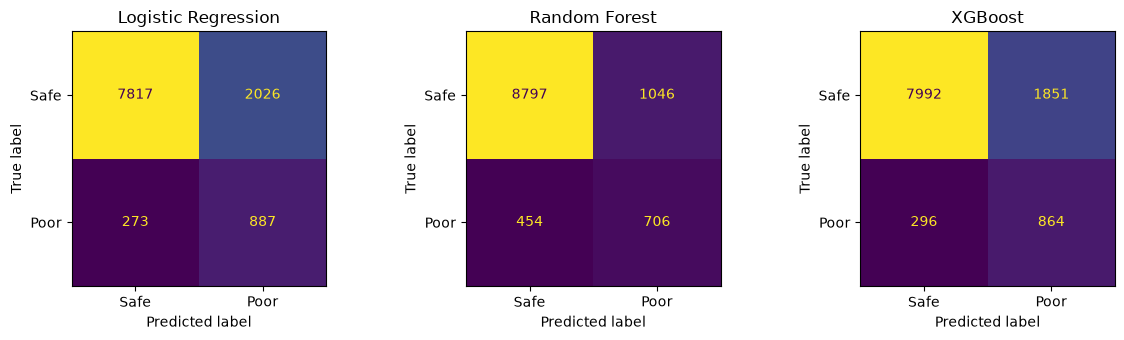

In [21]:
fig, axes = plt.subplots(1, len(models), figsize=(4 * len(models), 3.5))
for ax, (name, model) in zip(axes, models.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, model.predict(X_test)),
                           display_labels=['Safe', 'Poor']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [22]:
# Per-site results for the model with the best CV F1 (chosen without peeking at the test set)
best = cv_results['CV F1 (poor)'].idxmax()
test_pred = test.assign(pred=models[best].predict(X_test))

site_rows = []
for site, s in test_pred.groupby('site'):
    site_rows.append({'site': site, 'samples': len(s), 'poor days': s['poor'].sum(),
                      'recall (poor)': recall_score(s['poor'], s['pred'], zero_division=0),
                      'F1 (poor)': f1_score(s['poor'], s['pred'], zero_division=0)})
print('Model:', best)
pd.DataFrame(site_rows).set_index('site').sort_values('poor days', ascending=False).round(3)

Model: Random Forest


,samples,poor days,recall (poor),F1 (poor)
site,,,,
Bilarong Reserve,330,133,0.842,0.653
Narrabeen Lagoon (Birdwood Park),329,103,0.883,0.583
Bayview Baths,212,71,0.620,0.533
Shelly Beach (Manly),334,70,0.414,0.450
Queenscliff Beach,334,59,0.729,0.614
Davidson Reserve,218,54,0.926,0.649
South Steyne Beach,328,47,0.426,0.377
Gurney Crescent Baths,218,45,0.844,0.650
Freshwater Beach,335,36,0.361,0.321


## 11. Did expanding to all sites help the focus site?
Same models, trained on the focus site only, compared with the all-sites models, both scored on the focus site's test rows. If "all sites" wins, the extra data is helping.

In [23]:
focus_train = train[train['site'] == FOCUS_SITE]
focus_test = test[test['site'] == FOCUS_SITE]

rows = []
for name, model in models.items():
    solo = clone(model)
    if name == 'XGBoost':   # re-balance for the focus site's own class ratio
        solo.set_params(clf__scale_pos_weight=(focus_train['poor'] == 0).sum() / focus_train['poor'].sum())
    solo.fit(focus_train[FEATURES], focus_train['poor'])

    for trained_on, m in [('all sites', model), ('focus site only', solo)]:
        pred = m.predict(focus_test[FEATURES])
        rows.append({'model': name, 'trained on': trained_on,
                     'recall (poor)': recall_score(focus_test['poor'], pred),
                     'F1 (poor)': f1_score(focus_test['poor'], pred)})

print('Focus site:', FOCUS_SITE, '| test rows:', len(focus_test))
pd.DataFrame(rows).set_index(['model', 'trained on']).round(3)

Focus site: Narrabeen Lagoon (Birdwood Park) | test rows: 329


recall (poor)  F1 (poor)
model               trained on                               
Logistic Regression all sites                1.000      0.477
                    focus site only          0.631      0.610
Random Forest       all sites                0.883      0.583
                    focus site only          0.699      0.643
XGBoost             all sites                0.961      0.508
                    focus site only          0.602      0.588

## 12. Next steps — TODO
- [x] BOM daily rainfall merged (Section 5)
- [x] Expanded to all sites with site features (Section 6)
- [ ] Decision-threshold tuning using CV on the training years (never on test)
- [ ] Hyperparameter tuning with `TimeSeriesSplit`
- [ ] Feature importance / LR coefficients for interpretability
- [ ] Site-type feature (lagoon / harbour / ocean beach) or catchment data — stretch goal
- [ ] Extra BOM stations for Manly / Pittwater sites (rainfall currently from Collaroy + Mona Vale only)